# Pivot-Shifted Carleman Linearisation

Algorithm implementations: [`psc_logistic.py`](psc_logistic.py) · [`psc_lotka_volterra.py`](psc_lotka_volterra.py)

**Section 1** — Logistic model  
**Section 2** — Lotka-Volterra model

---
## Section 1 · Logistic Model

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.integrate import solve_ivp
from psc_logistic import ps_coeffs, solve_carleman_scalar

# ── Parameters ────────────────────────────────────────────────────────────────
r          = 1.0
x0         = 0.5
t0         = 0.0
T          = 10.0
num_tsteps = 2001
Deltat     = T / (num_tsteps - 1)
s1, s2     = 1.2, x0       # pivot values

t_eval  = np.linspace(t0, T, int(T / Deltat) + 1)
x_exact = (x0 * np.exp(r * t_eval)) / (1.0 + x0 * (np.exp(r * t_eval) - 1.0))

# ── Styling ───────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "text.usetex":         False,
    "mathtext.fontset":    "cm",
    "font.family":         "serif",
    "font.serif":          ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "axes.spines.top":     True,
    "axes.spines.right":   True,
    "axes.spines.bottom":  True,
    "axes.spines.left":    True,
    "figure.facecolor":    "white",
    "axes.facecolor":      "white",
    "savefig.facecolor":   "white",
    "font.size":           18,
})
pal8 = sns.color_palette("colorblind", n_colors=8)
col_carl   = pal8[0]
col_ps_s2  = pal8[1]
col_ps_s1  = pal8[2]
col_e_carl = pal8[0]
col_e_ps2  = pal8[1]
col_e_ps1  = pal8[2]

In [2]:
# ── Data: compute all trajectories and errors ─────────────────────────────────
F0, F1, F2       = 0.0, r, -r
F0s1, F1s1, F2s1 = ps_coeffs(r, s1)
F0s2, F1s2, F2s2 = ps_coeffs(r, s2)

# ── (a)/(b): N = 4 ────────────────────────────────────────────────────────────
N_ab = 4

_, Y_carl_1,  _, _ = solve_carleman_scalar(F0,   F1,   F2,   x0,      T, N_ab, Deltat)
_, Y_ps_s2_1, _, _ = solve_carleman_scalar(F0s2, F1s2, F2s2, x0 - s2, T, N_ab, Deltat)
_, Y_ps_s1_1, _, _ = solve_carleman_scalar(F0s1, F1s1, F2s1, x0 - s1, T, N_ab, Deltat)

traj_carl_1  = Y_carl_1[0]
traj_ps_s2_1 = Y_ps_s2_1[0] + s2
traj_ps_s1_1 = Y_ps_s1_1[0] + s1

err_carl_1  = np.abs(traj_carl_1  - x_exact)
err_ps_s2_1 = np.abs(traj_ps_s2_1 - x_exact)
err_ps_s1_1 = np.abs(traj_ps_s1_1 - x_exact)

# ── (c)/(d): N = 8 ────────────────────────────────────────────────────────────
N_cd = 8

_, Y_carl_4,  _, _ = solve_carleman_scalar(F0,   F1,   F2,   x0,      T, N_cd, Deltat)
_, Y_ps_s2_4, _, _ = solve_carleman_scalar(F0s2, F1s2, F2s2, x0 - s2, T, N_cd, Deltat)
_, Y_ps_s1_4, _, _ = solve_carleman_scalar(F0s1, F1s1, F2s1, x0 - s1, T, N_cd, Deltat)

traj_carl_4  = Y_carl_4[0]
traj_ps_s2_4 = Y_ps_s2_4[0] + s2
traj_ps_s1_4 = Y_ps_s1_4[0] + s1

err_carl_4  = np.abs(traj_carl_4  - x_exact)
err_ps_s2_4 = np.abs(traj_ps_s2_4 - x_exact)
err_ps_s1_4 = np.abs(traj_ps_s1_4 - x_exact)

# ── (e): error at T vs truncation order ───────────────────────────────────────
Nind_e          = range(1, 70)
err_final_carl  = np.zeros(len(Nind_e))
err_final_ps_s1 = np.zeros(len(Nind_e))
err_final_ps_s2 = np.zeros(len(Nind_e))

for i, N in enumerate(Nind_e):
    _, Y, _, _ = solve_carleman_scalar(F0,   F1,   F2,   x0,      T, N, Deltat)
    err_final_carl[i] = np.abs(Y[0, -1] - x_exact[-1])
    _, Y, _, _ = solve_carleman_scalar(F0s1, F1s1, F2s1, x0 - s1, T, N, Deltat)
    err_final_ps_s1[i] = np.abs(Y[0, -1] + s1 - x_exact[-1])
    _, Y, _, _ = solve_carleman_scalar(F0s2, F1s2, F2s2, x0 - s2, T, N, Deltat)
    err_final_ps_s2[i] = np.abs(Y[0, -1] + s2 - x_exact[-1])

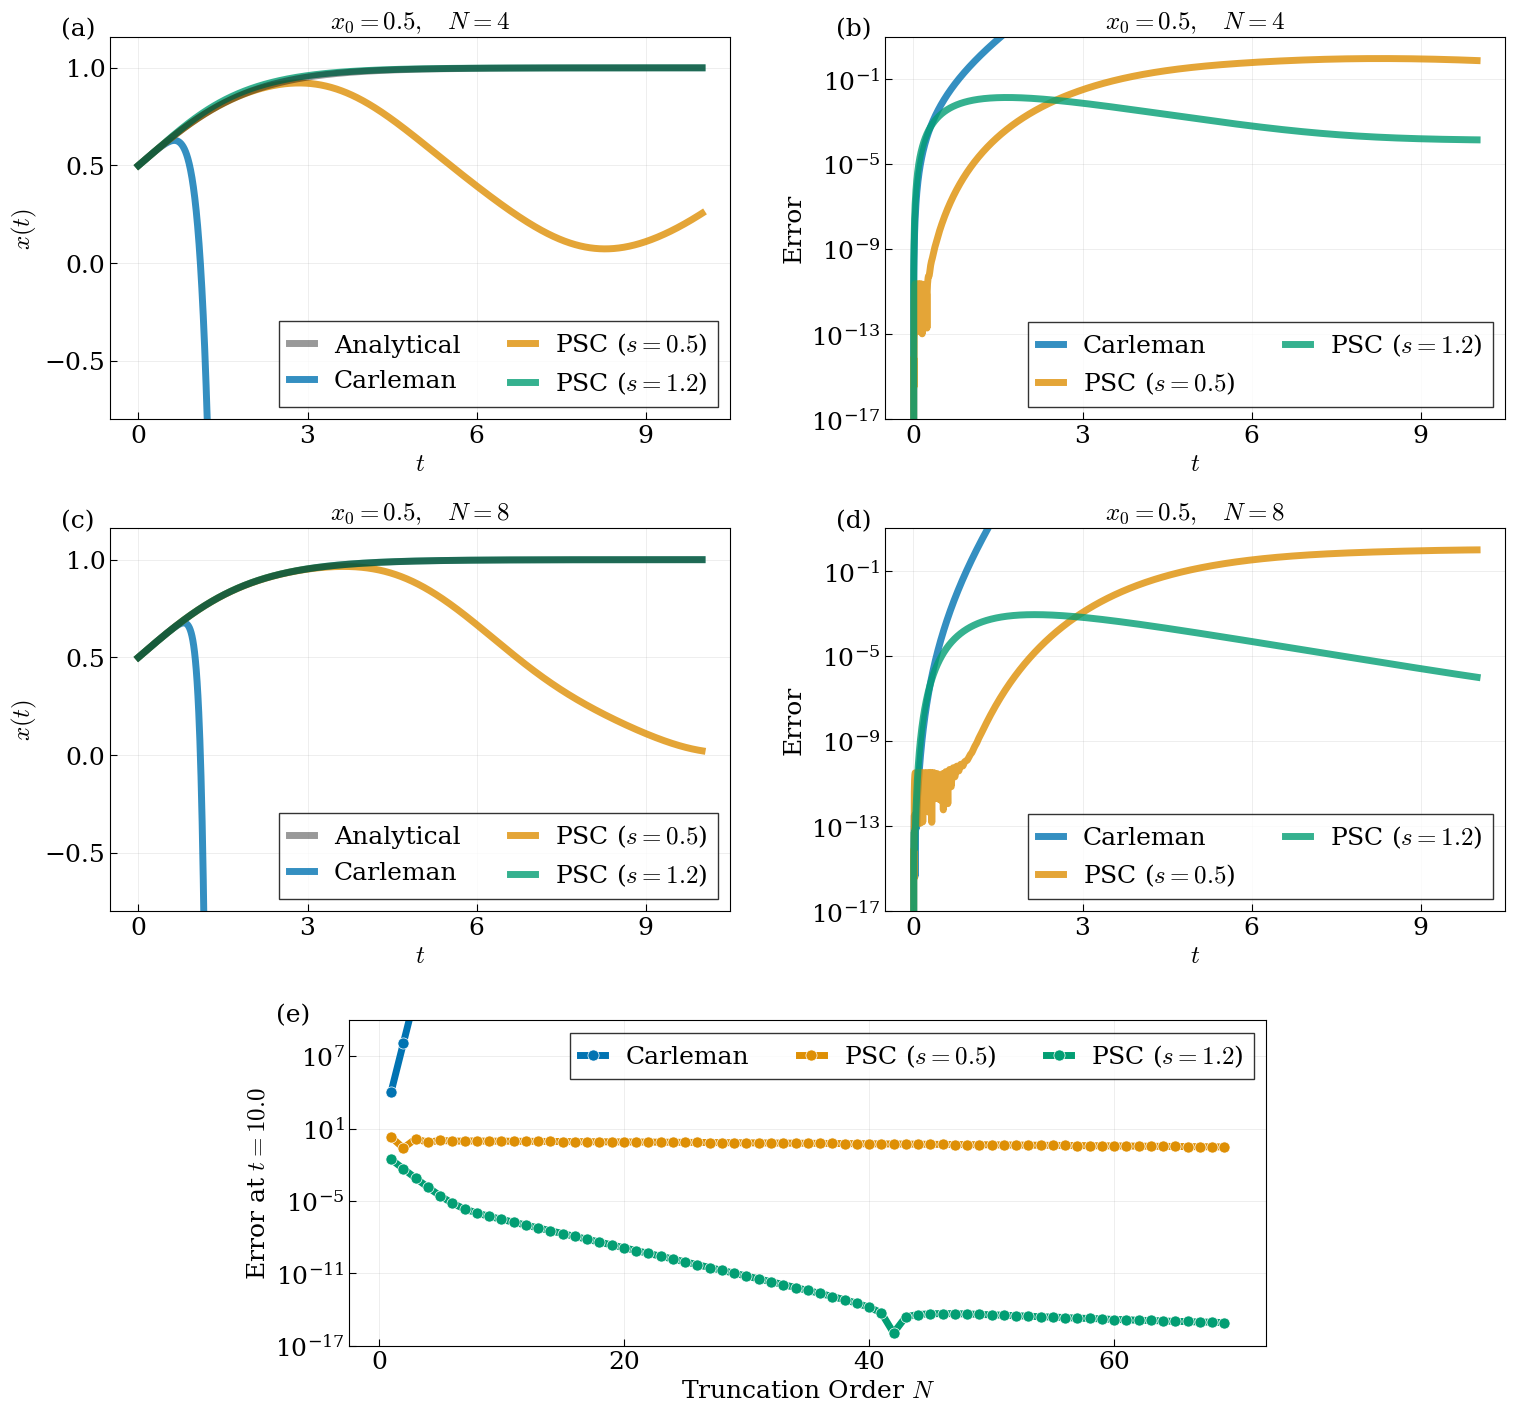

Saved logistic_model.pdf


In [3]:
# ── Combined figure: row 1 (a,b), row 2 (c,d), row 3 (e) centred ─────────────
from matplotlib.ticker import LogLocator

FS = 18
LW = 5.0

fig = plt.figure(figsize=(18, 17))
gs_outer = gridspec.GridSpec(3, 1, figure=fig, hspace=0.3,
                             height_ratios=[1, 1, 0.85])
gs_top   = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0], wspace=0.25)
gs_mid   = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[1], wspace=0.25)
gs_bot   = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=gs_outer[2])

ax_a = fig.add_subplot(gs_top[0])
ax_b = fig.add_subplot(gs_top[1])
ax_c = fig.add_subplot(gs_mid[0])
ax_d = fig.add_subplot(gs_mid[1])
ax_e = fig.add_subplot(gs_bot[0, 1:5])

for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    for spine in ax.spines.values():
        spine.set_visible(True)

# ==============================================================================
# Panel (a) — trajectories x(t) for N=4
# ==============================================================================
ax_a.plot(t_eval, x_exact,      "-",  color="black",   lw=LW, label="Analytical", zorder=5, alpha=0.4)
ax_a.plot(t_eval, traj_carl_1,  "-",  color=col_carl,  lw=LW, label=fr"Carleman", alpha=0.8)
ax_a.plot(t_eval, traj_ps_s2_1, "-",  color=col_ps_s2, lw=LW, label=fr"PSC ($s={s2}$)", alpha=0.8)
ax_a.plot(t_eval, traj_ps_s1_1, "-",  color=col_ps_s1, lw=LW, label=fr"PSC ($s={s1}$)", alpha=0.8)

ax_a.set_xlabel(r"$t$",    fontsize=FS)
ax_a.set_ylabel(r"$x(t)$", fontsize=FS)
ax_a.set_ylim(-0.8, 1.16)
ax_a.legend(frameon=True, fancybox=False, edgecolor="black",
            fontsize=FS, ncol=2, loc="lower right", handlelength=1)
ax_a.set_title("$x_0=0.5, \\quad N=4$", fontsize=FS)
ax_a.grid(True, alpha=0.25, lw=0.6)
ax_a.text(-0.08, 1.05, r"(a)", transform=ax_a.transAxes,
          ha="left", va="top", fontsize=FS, color="black")

# ==============================================================================
# Panel (b) — error vs time for N=4
# ==============================================================================
ax_b.semilogy(t_eval, err_carl_1,  "-",  color=col_carl,  lw=LW, label=fr"Carleman", alpha=0.8)
ax_b.semilogy(t_eval, err_ps_s2_1, "-",  color=col_ps_s2, lw=LW, label=fr"PSC ($s={s2}$)", alpha=0.8)
ax_b.semilogy(t_eval, err_ps_s1_1, "-",  color=col_ps_s1, lw=LW, label=fr"PSC ($s={s1}$)", alpha=0.8)

ax_b.set_xlabel(r"$t$",  fontsize=FS)
ax_b.set_ylabel("Error", fontsize=FS)
ax_b.set_ylim(1e-17, 1e1)
ax_b.legend(frameon=True, fancybox=False, edgecolor="black",
            fontsize=FS, ncol=2, loc="lower right", handlelength=1)
ax_b.set_title("$x_0=0.5, \\quad N=4$", fontsize=FS)
ax_b.grid(True, alpha=0.25, lw=0.6)
ax_b.text(-0.08, 1.05, r"(b)", transform=ax_b.transAxes,
          ha="left", va="top", fontsize=FS, color="black")

# ==============================================================================
# Panel (c) — trajectories x(t) for N=8
# ==============================================================================
ax_c.plot(t_eval, x_exact,      "-",  color="black",   lw=LW, label="Analytical", zorder=5, alpha=0.4)
ax_c.plot(t_eval, traj_carl_4,  "-",  color=col_carl,  lw=LW, label=fr"Carleman", alpha=0.8)
ax_c.plot(t_eval, traj_ps_s2_4, "-",  color=col_ps_s2, lw=LW, label=fr"PSC ($s={s2}$)", alpha=0.8)
ax_c.plot(t_eval, traj_ps_s1_4, "-",  color=col_ps_s1, lw=LW, label=fr"PSC ($s={s1}$)", alpha=0.8)

ax_c.set_xlabel(r"$t$",    fontsize=FS)
ax_c.set_ylabel(r"$x(t)$", fontsize=FS)
ax_c.set_ylim(-0.8, 1.16)
ax_c.legend(frameon=True, fancybox=False, edgecolor="black",
            fontsize=FS, ncol=2, loc="lower right", handlelength=1)
ax_c.set_title("$x_0=0.5, \\quad N=8$", fontsize=FS)
ax_c.grid(True, alpha=0.25, lw=0.6)
ax_c.text(-0.08, 1.05, r"(c)", transform=ax_c.transAxes,
          ha="left", va="top", fontsize=FS, color="black")

# ==============================================================================
# Panel (d) — error vs time for N=8
# ==============================================================================
ax_d.semilogy(t_eval, err_carl_4,  "-",  color=col_carl,  lw=LW, label=fr"Carleman", alpha=0.8)
ax_d.semilogy(t_eval, err_ps_s2_4, "-",  color=col_ps_s2, lw=LW, label=fr"PSC ($s={s2}$)", alpha=0.8)
ax_d.semilogy(t_eval, err_ps_s1_4, "-",  color=col_ps_s1, lw=LW, label=fr"PSC ($s={s1}$)", alpha=0.8)

ax_d.set_xlabel(r"$t$",  fontsize=FS)
ax_d.set_ylabel("Error", fontsize=FS)
ax_d.legend(frameon=True, fancybox=False, edgecolor="black",
            fontsize=FS, ncol=2, loc="lower right", handlelength=1)
ax_d.set_title("$x_0=0.5, \\quad N=8$", fontsize=FS)
ax_d.set_ylim(1e-17, 1e1)
ax_d.grid(True, alpha=0.25, lw=0.6)
ax_d.text(-0.08, 1.05, r"(d)", transform=ax_d.transAxes,
          ha="left", va="top", fontsize=FS, color="black")

# ==============================================================================
# Panel (e) — error at final time vs truncation order N
# ==============================================================================
Nind_e_list = list(Nind_e)

ax_e.semilogy(Nind_e_list, err_final_carl,  "o-",
              color=col_e_carl, lw=LW, ms=8, markeredgecolor="white", markeredgewidth=0.5,
              label="Carleman")
ax_e.semilogy(Nind_e_list, err_final_ps_s2, "o-",
              color=col_e_ps2,  lw=LW, ms=8, markeredgecolor="white", markeredgewidth=0.5,
              label=fr"PSC ($s={s2}$)")
ax_e.semilogy(Nind_e_list, err_final_ps_s1, "o-",
              color=col_e_ps1,  lw=LW, ms=8, markeredgecolor="white", markeredgewidth=0.5,
              label=fr"PSC ($s={s1}$)")

ax_e.set_xlabel(r"Truncation Order $N$", fontsize=FS)
ax_e.set_ylabel(rf"Error at $t={int(T)}.0$", fontsize=FS)
ax_e.set_ylim(1e-17, 1e10)
ax_e.legend(frameon=True, fancybox=False, edgecolor="black",
            fontsize=FS, loc="best", ncol=3, handlelength=1)
ax_e.grid(True, alpha=0.25, lw=0.6)
ax_e.text(-0.08, 1.05, r"(e)",
          transform=ax_e.transAxes, ha="left", va="top", fontsize=FS, color="black")

# ── Tick style ────────────────────────────────────────────────────────────────
for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    ax.tick_params(which="both", direction="in",
                   top=False, right=False, length=5, labelsize=FS)

for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))

for ax in [ax_a, ax_c]:
    ax.yaxis.set_major_locator(plt.MaxNLocator(4))

for ax in [ax_b, ax_d, ax_e]:
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=5))

# plt.savefig("logistic_model.pdf", format="pdf", bbox_inches="tight")
plt.show()
print("Saved logistic_model.pdf")

---
## Section 2 · Lotka-Volterra Model

In [4]:
# ── Imports ───────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.integrate import solve_ivp
from psc_lotka_volterra import lv_rhs, solve_carleman

# ── Parameters ────────────────────────────────────────────────────────────────
eta    = 1.0
gamma  = 0.475
theta0 = np.array([0.5, 0.5])
s_ps   = np.array([0.7, 0.3])

t_end_traj = 5.0
n_pts_traj = 2000
t_end_e    = 2.0
n_pts_e    = 800
Nind_e     = list(range(1, 12))

# ── Styling ───────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'text.usetex':         False,
    'mathtext.fontset':    'cm',
    'font.family':         'serif',
    'font.serif':          ['Computer Modern Roman', 'DejaVu Serif', 'Times New Roman'],
    'axes.spines.top':     True,
    'axes.spines.right':   True,
    'axes.spines.bottom':  True,
    'axes.spines.left':    True,
    'figure.facecolor':    'white',
    'axes.facecolor':      'white',
    'savefig.facecolor':   'white',
    'font.size':           18,
})
pal8        = sns.color_palette('colorblind', n_colors=8)
col_rk45    = 'black'
col_carl    = pal8[0]
col_ps_t0   = pal8[1]
col_ps_s    = pal8[2]
col_e_carl  = pal8[0]
col_e_ps_t0 = pal8[1]
col_e_ps_s  = pal8[2]

In [5]:
# ── Data: compute all trajectories and errors ─────────────────────────────────

# Reference solution for panels (a)–(d)
t_eval_traj = np.linspace(0.0, t_end_traj, n_pts_traj)
sol_ref = solve_ivp(lambda t, x: lv_rhs(t, x, eta, gamma),
                    (0.0, t_end_traj), theta0, t_eval=t_eval_traj,
                    method='RK45', rtol=1e-14, atol=1e-14)
x_ex = sol_ref.y

# ── (a)/(b): N = 4 ────────────────────────────────────────────────────────────
N4 = 4
traj_carl_4  = solve_carleman(theta0, t_eval_traj, N4, eta, gamma)
traj_ps_t0_4 = solve_carleman(theta0, t_eval_traj, N4, eta, gamma, pivot=theta0)
traj_ps_s_4  = solve_carleman(theta0, t_eval_traj, N4, eta, gamma, pivot=s_ps)

err_carl_4  = np.linalg.norm(traj_carl_4  - x_ex, axis=0)
err_ps_t0_4 = np.linalg.norm(traj_ps_t0_4 - x_ex, axis=0)
err_ps_s_4  = np.linalg.norm(traj_ps_s_4  - x_ex, axis=0)

# ── (c)/(d): N = 8 ────────────────────────────────────────────────────────────
N8 = 8
traj_carl_8  = solve_carleman(theta0, t_eval_traj, N8, eta, gamma)
traj_ps_t0_8 = solve_carleman(theta0, t_eval_traj, N8, eta, gamma, pivot=theta0)
traj_ps_s_8  = solve_carleman(theta0, t_eval_traj, N8, eta, gamma, pivot=s_ps)

err_carl_8  = np.linalg.norm(traj_carl_8  - x_ex, axis=0)
err_ps_t0_8 = np.linalg.norm(traj_ps_t0_8 - x_ex, axis=0)
err_ps_s_8  = np.linalg.norm(traj_ps_s_8  - x_ex, axis=0)

# ── (e): error at final time vs truncation order N ───────────────────────────
t_eval_e = np.linspace(0.0, t_end_e, n_pts_e)
sol_e    = solve_ivp(lambda t, x: lv_rhs(t, x, eta, gamma),
                     (0.0, t_end_e), theta0, t_eval=t_eval_e,
                     method='RK45', rtol=1e-14, atol=1e-14)
x_ex_e_final = sol_e.y[:, -1]

err_e_carl  = np.zeros(len(Nind_e))
err_e_ps_t0 = np.zeros(len(Nind_e))
err_e_ps_s  = np.zeros(len(Nind_e))
for i, N in enumerate(Nind_e):
    xc             = solve_carleman(theta0, t_eval_e, N, eta, gamma)
    err_e_carl[i]  = np.linalg.norm(xc[:, -1] - x_ex_e_final)
    xp_t0          = solve_carleman(theta0, t_eval_e, N, eta, gamma, pivot=theta0)
    err_e_ps_t0[i] = np.linalg.norm(xp_t0[:, -1] - x_ex_e_final)
    xp_s           = solve_carleman(theta0, t_eval_e, N, eta, gamma, pivot=s_ps)
    err_e_ps_s[i]  = np.linalg.norm(xp_s[:, -1] - x_ex_e_final)

/opt/miniconda3/envs/qmlenv/lib/python3.11/site-packages/scipy/integrate/_ivp/ivp.py:621: UserWarning: At least one element of `rtol` is too small. Setting `rtol = np.maximum(rtol, 2.220446049250313e-14)`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


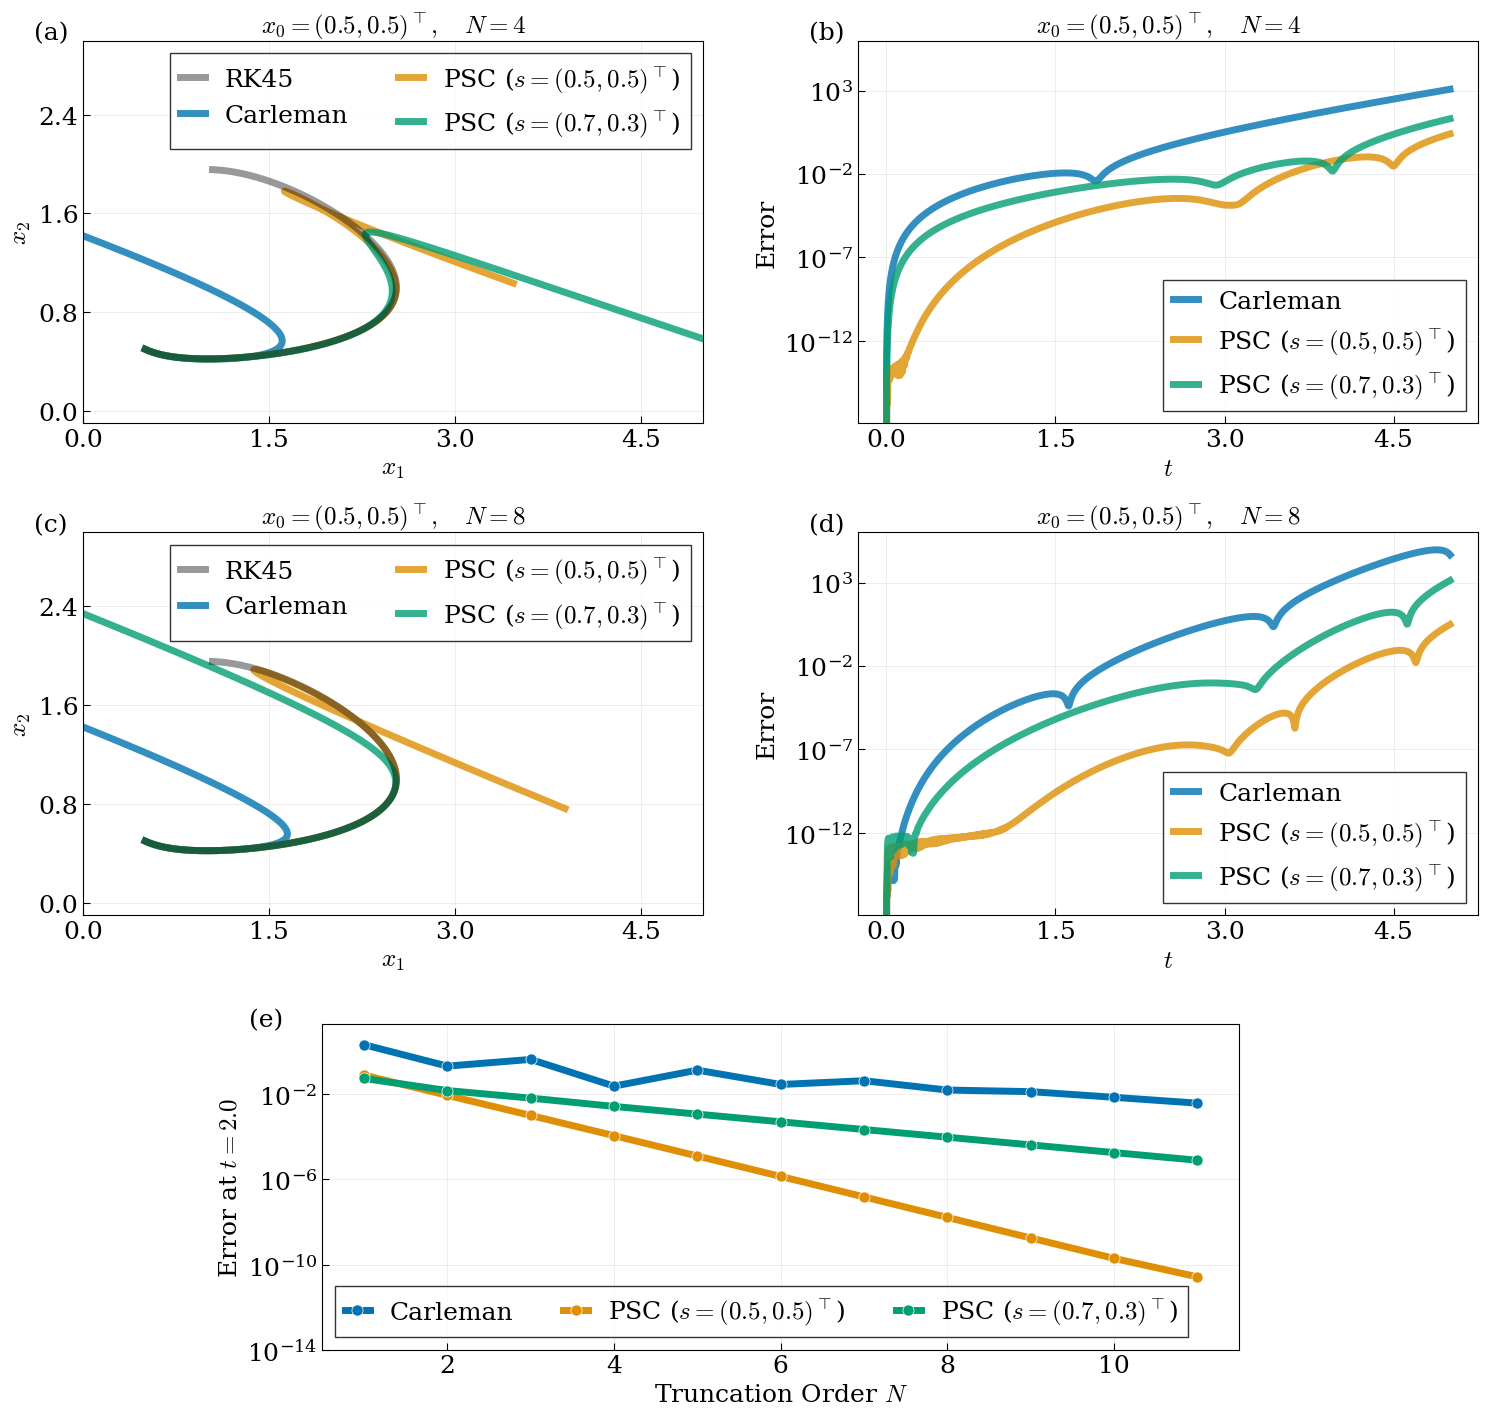

Saved lotka_volterra_model.pdf


In [6]:
# ── Combined figure: row 1 (a,b), row 2 (c,d), row 3 (e) centred ─────────────
from matplotlib.ticker import LogLocator

FS = 18
LW = 5.0

fig = plt.figure(figsize=(18, 17))
gs_outer = gridspec.GridSpec(3, 1, figure=fig, hspace=0.3,
                             height_ratios=[1, 1, 0.85])
gs_top = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0], wspace=0.25)
gs_mid = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[1], wspace=0.25)
gs_bot = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=gs_outer[2])

ax_a = fig.add_subplot(gs_top[0])
ax_b = fig.add_subplot(gs_top[1])
ax_c = fig.add_subplot(gs_mid[0])
ax_d = fig.add_subplot(gs_mid[1])
ax_e = fig.add_subplot(gs_bot[0, 1:5])

for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    for spine in ax.spines.values():
        spine.set_visible(True)

# ==============================================================================
# Panel (a) — phase plane, N = 4
# ==============================================================================
ax_a.plot(x_ex[0], x_ex[1], '-',  color=col_rk45,  lw=LW, label='RK45', zorder=5, alpha=0.4)
ax_a.plot(traj_carl_4[0],  traj_carl_4[1],  '-', color=col_carl,  lw=LW,
          label=r'Carleman', alpha=0.8)
ax_a.plot(traj_ps_t0_4[0], traj_ps_t0_4[1], '-', color=col_ps_t0, lw=LW,
          label=r'PSC ($s=(0.5,0.5)^\top$)', alpha=0.8)
ax_a.plot(traj_ps_s_4[0],  traj_ps_s_4[1],  '-', color=col_ps_s,  lw=LW,
          label=r'PSC ($s=(0.7,0.3)^\top$)', alpha=0.8)

ax_a.set_xlabel(r'$x_1$', fontsize=FS)
ax_a.set_ylabel(r'$x_2$', fontsize=FS)
ax_a.set_xlim(0, 5)
ax_a.set_ylim(-0.1, 3)
ax_a.legend(frameon=True, fancybox=False, edgecolor='black',
            fontsize=FS, ncol=2, loc='best', handlelength=1)
ax_a.set_title(r'$x_0=(0.5, 0.5)^\top,\quad N=4$', fontsize=FS)
ax_a.grid(True, alpha=0.25, lw=0.6)
ax_a.text(-0.08, 1.05, r'(a)', transform=ax_a.transAxes,
          ha='left', va='top', fontsize=FS, color='black')

# ==============================================================================
# Panel (b) — error vs time, N = 4
# ==============================================================================
ax_b.semilogy(t_eval_traj, err_carl_4,  '-', color=col_carl,  lw=LW,
              label=r'Carleman', alpha=0.8)
ax_b.semilogy(t_eval_traj, err_ps_t0_4, '-', color=col_ps_t0, lw=LW,
              label=r'PSC ($s=(0.5,0.5)^\top$)', alpha=0.8)
ax_b.semilogy(t_eval_traj, err_ps_s_4,  '-', color=col_ps_s,  lw=LW,
              label=r'PSC ($s=(0.7,0.3)^\top$)', alpha=0.8)

ax_b.set_xlabel(r'$t$',   fontsize=FS)
ax_b.set_ylabel('Error',  fontsize=FS)
ax_b.set_ylim(1.1221719818126345e-17, 1032255.8562994868)
ax_b.legend(frameon=True, fancybox=False, edgecolor='black',
            fontsize=FS, ncol=1, loc='best', handlelength=1)
ax_b.set_title(r'$x_0=(0.5, 0.5)^\top,\quad N=4$', fontsize=FS)
ax_b.grid(True, alpha=0.25, lw=0.6)
ax_b.text(-0.08, 1.05, r'(b)', transform=ax_b.transAxes,
          ha='left', va='top', fontsize=FS, color='black')

# ==============================================================================
# Panel (c) — phase plane, N = 8
# ==============================================================================
ax_c.plot(x_ex[0], x_ex[1], '-',  color=col_rk45,  lw=LW, label='RK45', zorder=5, alpha=0.4)
ax_c.plot(traj_carl_8[0],  traj_carl_8[1],  '-', color=col_carl,  lw=LW,
          label=r'Carleman', alpha=0.8)
ax_c.plot(traj_ps_t0_8[0], traj_ps_t0_8[1], '-', color=col_ps_t0, lw=LW,
          label=r'PSC ($s=(0.5,0.5)^\top$)', alpha=0.8)
ax_c.plot(traj_ps_s_8[0],  traj_ps_s_8[1],  '-', color=col_ps_s,  lw=LW,
          label=r'PSC ($s=(0.7,0.3)^\top$)', alpha=0.8)

ax_c.set_xlabel(r'$x_1$', fontsize=FS)
ax_c.set_ylabel(r'$x_2$', fontsize=FS)
ax_c.set_xlim(0, 5)
ax_c.set_ylim(-0.1, 3)
ax_c.legend(frameon=True, fancybox=False, edgecolor='black',
            fontsize=FS, ncol=2, loc='best', handlelength=1)
ax_c.set_title(r'$x_0=(0.5, 0.5)^\top,\quad N=8$', fontsize=FS)
ax_c.grid(True, alpha=0.25, lw=0.6)
ax_c.text(-0.08, 1.05, r'(c)', transform=ax_c.transAxes,
          ha='left', va='top', fontsize=FS, color='black')

# ==============================================================================
# Panel (d) — error vs time, N = 8
# ==============================================================================
ax_d.semilogy(t_eval_traj, err_carl_8,  '-', color=col_carl,  lw=LW,
              label=r'Carleman', alpha=0.8)
ax_d.semilogy(t_eval_traj, err_ps_t0_8, '-', color=col_ps_t0, lw=LW,
              label=r'PSC ($s=(0.5,0.5)^\top$)', alpha=0.8)
ax_d.semilogy(t_eval_traj, err_ps_s_8,  '-', color=col_ps_s,  lw=LW,
              label=r'PSC ($s=(0.7,0.3)^\top$)', alpha=0.8)

ax_d.set_xlabel(r'$t$',   fontsize=FS)
ax_d.set_ylabel('Error',  fontsize=FS)
ax_d.legend(frameon=True, fancybox=False, edgecolor='black',
            fontsize=FS, ncol=1, loc='best', handlelength=1)
ax_d.set_title(r'$x_0=(0.5, 0.5)^\top,\quad N=8$', fontsize=FS)
ax_d.grid(True, alpha=0.25, lw=0.6)
ax_d.text(-0.08, 1.05, r'(d)', transform=ax_d.transAxes,
          ha='left', va='top', fontsize=FS, color='black')

# ==============================================================================
# Panel (e) — error at final time vs truncation order N
# ==============================================================================
ax_e.semilogy(Nind_e, err_e_carl,  'o-', color=col_e_carl,  lw=LW, ms=8,
              markeredgecolor='white', markeredgewidth=0.5, label='Carleman')
ax_e.semilogy(Nind_e, err_e_ps_t0, 'o-', color=col_e_ps_t0, lw=LW, ms=8,
              markeredgecolor='white', markeredgewidth=0.5,
              label=r'PSC ($s=(0.5,0.5)^\top$)')
ax_e.semilogy(Nind_e, err_e_ps_s,  'o-', color=col_e_ps_s,  lw=LW, ms=8,
              markeredgecolor='white', markeredgewidth=0.5,
              label=r'PSC ($s=(0.7,0.3)^{\top}$)')

ax_e.set_xlabel(r'Truncation Order $N$', fontsize=FS)
ax_e.set_ylabel(rf'Error at $t={t_end_e}$', fontsize=FS)
ax_e.set_ylim(1e-14, 2e1)
ax_e.legend(frameon=True, fancybox=False, edgecolor='black',
            fontsize=FS, ncol=3, loc='best', handlelength=1)
ax_e.grid(True, alpha=0.25, lw=0.6)
ax_e.text(-0.08, 1.05, r'(e)', transform=ax_e.transAxes,
          ha='left', va='top', fontsize=FS, color='black')

# ── Tick style ────────────────────────────────────────────────────────────────
for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    ax.tick_params(which='both', direction='in',
                   top=False, right=False, length=5, labelsize=FS)

for ax in [ax_b, ax_d]:
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))

for ax in [ax_a, ax_c]:
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.yaxis.set_major_locator(plt.MaxNLocator(4))

for ax in [ax_b, ax_d, ax_e]:
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=5))

# plt.savefig('lotka_volterra_model.pdf', format='pdf', bbox_inches='tight')
plt.show()
print('Saved lotka_volterra_model.pdf')